In [2]:
import pandas as pd
dolar= pd.read_excel("dolar_verisi.xlsx")
print(dolar.head())

     Tarih TP_DK_USD_S_YTL Unnamed: 2
0  01-2021        7.407285        NaN
1  02-2021        7.085125        NaN
2  03-2021         7.64197        NaN
3  04-2021        8.169719        NaN
4  05-2021        8.357272        NaN


C:\Users\yahya\anaconda3\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [3]:
print("veri setinin boyutu:")
print(dolar.shape)

print("\nSütun bilgileri:")
print(dolar.columns)

print("\nVeri seti hakkında bilgi:")
print(dolar.info())

print("\nEksik değerleri:")
print(dolar.isnull().sum())

veri setinin boyutu:
(68, 3)

Sütun bilgileri:
Index(['Tarih', 'TP_DK_USD_S_YTL', 'Unnamed: 2'], dtype='str')

Veri seti hakkında bilgi:
<class 'pandas.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Tarih            64 non-null     str   
 1   TP_DK_USD_S_YTL  63 non-null     object
 2   Unnamed: 2       3 non-null      str   
dtypes: object(1), str(2)
memory usage: 2.3+ KB
None

Eksik değerleri:
Tarih               4
TP_DK_USD_S_YTL     5
Unnamed: 2         65
dtype: int64


In [10]:
# gereksiz sütunu kaldırıyoruz
dolar = dolar[["Tarih", "TP_DK_USD_S_YTL"]].copy()

# sütun isimlerini sadeleştiryoruz
dolar.columns = ["Tarih", "Dolar_kuru"]

# tarihleri tarih formatına çeviriyoruz
dolar["Tarih"] = pd.to_datetime(
    dolar["Tarih"],
    format="%m-%Y",
    errors="coerce"
)
# dolar kurunu sayısal formata çeviriyoruz
dolar["Dolar_kuru"] = pd.to_numeric(
    dolar["Dolar_kuru"],
    errors="coerce"
)
# eksik gözlemleri kaldırıyoruz
dolar = dolar.dropna()

# tarihe göre sıralıyoruz
dolar = dolar.sort_values("Tarih").reset_index(drop=True)

# temizlenmiş veri setini inceliyoruz
print(dolar.info())
print(dolar.head())
print("yeni veri boyutu:", dolar.shape)

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Tarih       60 non-null     datetime64[us]
 1   Dolar_kuru  60 non-null     float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.1 KB
None
       Tarih  Dolar_kuru
0 2021-01-01    7.407285
1 2021-02-01    7.085125
2 2021-03-01    7.641970
3 2021-04-01    8.169719
4 2021-05-01    8.357272
yeni veri boyutu: (60, 2)


In [11]:
print("Eksik değerler:")
print(dolar.isnull().sum())

print("\nİlk 5 kayıt:")
print(dolar.head())

print("\nSon 5 kayıt:")
print(dolar.tail())

print("\nTarih aralığı:")
print(dolar["Tarih"].min())
print(dolar["Tarih"].max())

Eksik değerler:
Tarih         0
Dolar_kuru    0
dtype: int64

İlk 5 kayıt:
       Tarih  Dolar_kuru
0 2021-01-01    7.407285
1 2021-02-01    7.085125
2 2021-03-01    7.641970
3 2021-04-01    8.169719
4 2021-05-01    8.357272

Son 5 kayıt:
        Tarih  Dolar_kuru
55 2025-08-01   40.801695
56 2025-09-01   41.293473
57 2025-10-01   41.805418
58 2025-11-01   42.255160
59 2025-12-01   42.662813

Tarih aralığı:
2021-01-01 00:00:00
2025-12-01 00:00:00


In [12]:
print(dolar["Dolar_kuru"].describe())

count    60.000000
mean     24.297240
std      11.352633
min       7.085125
25%      14.680479
50%      24.788190
75%      34.080995
max      42.662813
Name: Dolar_kuru, dtype: float64


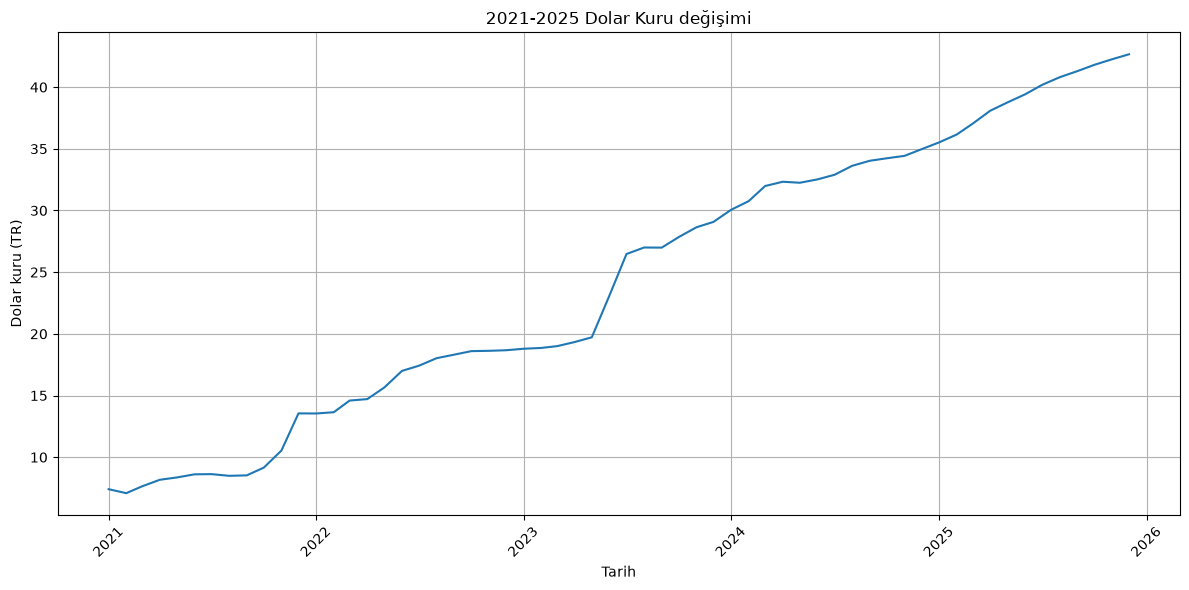

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(
    dolar["Tarih"],
    dolar["Dolar_kuru"],
)

plt.title("2021-2025 Dolar Kuru değişimi")
plt.xlabel("Tarih")
plt.ylabel("Dolar kuru (TR)")

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [17]:
print("ortalama:", dolar["Dolar_kuru"].mean())
print("medyan:", dolar["Dolar_kuru"].median())
print("standart sapma:", dolar["Dolar_kuru"].std())
print("minimum:", dolar["Dolar_kuru"].min())
print("maxsimum:", dolar["Dolar_kuru"].max())

ortalama: 24.297239926166665
medyan: 24.788190104999998
standart sapma: 11.352633361755158
minimum: 7.085125
maxsimum: 42.66281304


In [18]:
# yıllara göre son ayın dolar kurunu buluyoruz
yillik_kur = dolar.groupby(
    dolar["Tarih"].dt.year
)["Dolar_kuru"].last()
print(yillik_kur)

Tarih
2021    13.552861
2022    18.670545
2023    29.074857
2024    34.966705
2025    42.662813
Name: Dolar_kuru, dtype: float64


In [19]:
# yıllık yüzde değişim
yillik_degişim = yillik_kur.pct_change() * 100
print(yillik_degişim)

Tarih
2021          NaN
2022    37.760917
2023    55.725805
2024    20.264407
2025    22.009819
Name: Dolar_kuru, dtype: float64


In [20]:
sonuc = pd.DataFrame({
    "yıl sonu kuru": yillik_kur,
    "yıllık değişim (%)": yillik_degişim
})
print(sonuc.round(2))

       yıl sonu kuru  yıllık değişim (%)
Tarih                                   
2021           13.55                 NaN
2022           18.67               37.76
2023           29.07               55.73
2024           34.97               20.26
2025           42.66               22.01


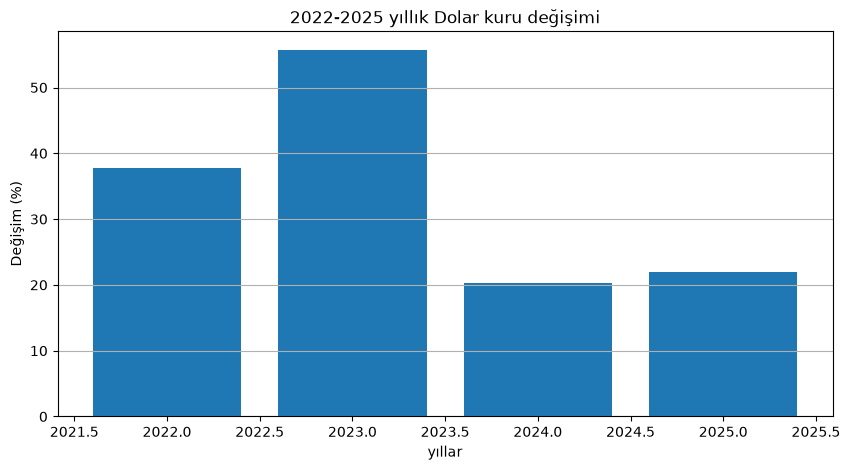

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.bar(
    yillik_degişim.index[1:],
    yillik_degişim.dropna()
)
plt.title("2022-2025 yıllık Dolar kuru değişimi")
plt.xlabel("yıllar")
plt.ylabel("Değişim (%)")

plt.grid(axis="y")
plt.show()

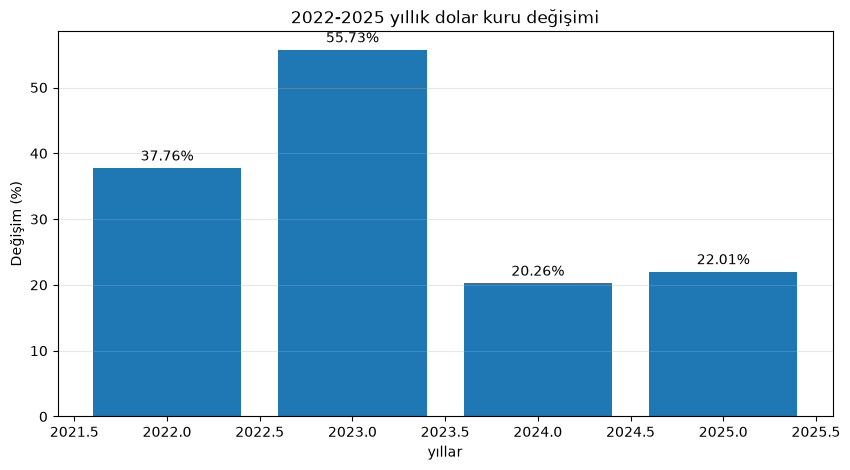

In [22]:
plt.figure(figsize=(10,5))
bars = plt.bar(
    yillik_degişim.index[1:],
    yillik_degişim.dropna()
)
plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("2022-2025 yıllık dolar kuru değişimi")
plt.xlabel("yıllar")
plt.ylabel("Değişim (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()
    

In [23]:
import numpy as np
from scipy.stats import linregress

# zaman değişkeni oluşturma
dolar["zaman"] = np.arange(len(dolar))

# regresyon anlizi
model = linregress(dolar["zaman"], dolar["Dolar_kuru"])

print("sabit terim:", model.intercept)
print("eğim katsayısı:", model.slope)
print("R kare:", model.rvalue**2)
print("p değeri:", model.pvalue)

sabit terim: 5.2486456482732216
eğim katsayısı: 0.6457150602675743
R kare: 0.9867075382449656
p değeri: 4.0338494118728866e-56


In [24]:
korelasyon = dolar["zaman"].corr(dolar["Dolar_kuru"])
print("korelasyon katsayısı:", korelasyon)

korelasyon katsayısı: 0.9933315349091487


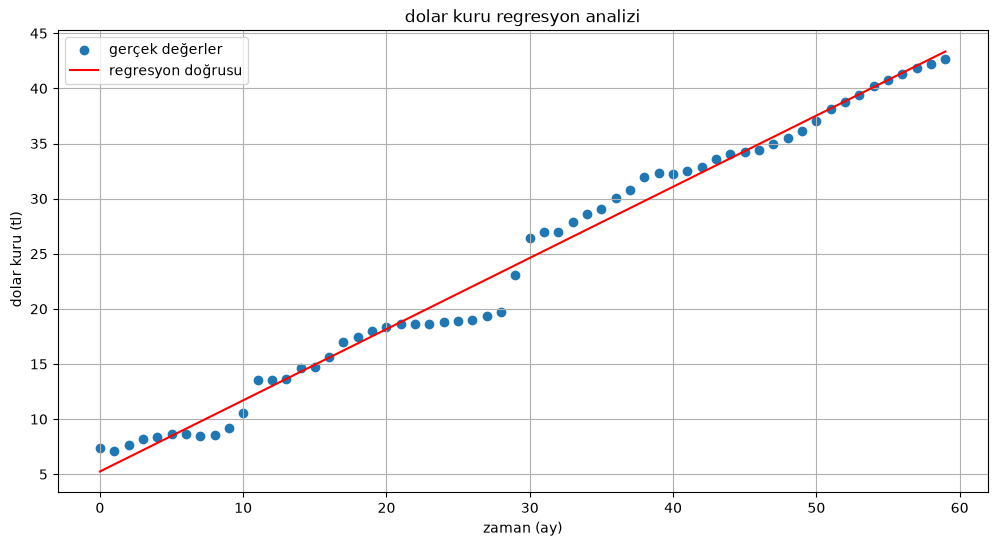

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.scatter(dolar["zaman"], dolar["Dolar_kuru"],
            label="gerçek değerler")
plt.plot(dolar["zaman"], model.intercept +
         model.slope * dolar["zaman"],
         color="red", label="regresyon doğrusu")

plt.title("dolar kuru regresyon analizi")
plt.xlabel("zaman (ay)")
plt.ylabel(" dolar kuru (tl)")

plt.legend()
plt.grid(True)
plt.show()

In [32]:
print("sabit katsayı:", model.intercept)
print("eğim katsayısı:", model.slope)
print("R kare:", model.rvalue**2)

sabit katsayı: 5.2486456482732216
eğim katsayısı: 0.6457150602675743
R kare: 0.9867075382449656
